# 03 - Classifier comparison

**Goal:** compare the six classifiers trained on the 380 classes of C3PI v2 (Kaggle, Optuna)
and the v1 champion, then look at the champion: confusion matrix and Grad-CAM of a correct and
a wrong prediction. Read from MLflow with `src/models/classification/compare.py`.

In [1]:
import os
import sys
import warnings
from pathlib import Path

os.environ.setdefault("MLFLOW_DISABLE_AGENT_HINT", "1")
os.environ.setdefault("MLFLOW_ENABLE_ARTIFACTS_PROGRESS_BAR", "false")
os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")
os.environ.setdefault("HF_HUB_DISABLE_IMPLICIT_TOKEN", "1")
ROOT = Path.cwd().resolve().parents[1]  # notebooks/<module>/ -> repository root
for path in (ROOT, ROOT / "backend"):
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))
os.chdir(ROOT)
warnings.filterwarnings("ignore")

import tempfile

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display
from PIL import Image

plt.rcParams.update({"figure.dpi": 72, "savefig.dpi": 72})
%config InlineBackend.figure_formats = ["jpeg"]
pd.set_option("display.max_colwidth", 90)


def fmt(frame, digits=3, **columns):
    """Format the float columns with f"{x:.{digits}f}", the rounding of the result tables."""
    out = frame.copy()
    for name in out.columns:
        if out[name].dtype.kind == "f":
            d = columns.get(name, digits)
            out[name] = out[name].map(lambda v, d=d: "" if pd.isna(v) else f"{v:.{d}f}")
    return out


def show_image(path, title="", width=480):
    """Display an image file, downscaled (the notebook stays small)."""
    import io

    from IPython.display import Image as JpegImage

    image = Image.open(path).convert("RGB")
    image.thumbnail((width, width))
    buffer = io.BytesIO()
    image.save(buffer, format="JPEG", quality=80)
    if title:
        display(Markdown(f"*{title}*"))
    display(JpegImage(data=buffer.getvalue(), format="jpeg"))

In [2]:
import mlflow

from src.utils import mlflow_utils as mu

mu.configure()  # tracking server of docker compose (http://127.0.0.1:5000), read only here
client = mlflow.MlflowClient()
TMP = Path(tempfile.mkdtemp(prefix="tujya-nb-"))  # downloaded artefacts stay outside the repo


def artefact(run_id, path):
    """Download one artefact of a run into a temporary folder and return its local path."""
    return Path(
        mlflow.artifacts.download_artifacts(run_id=run_id, artifact_path=path, dst_path=str(TMP))
    )


def champion(model):
    mv = client.get_model_version_by_alias(model, "champion")
    return mv.run_id, mv.version

## 1. Comparison table

Top-1, top-5 and macro F1 on the comparison split (1,131 crops); "v1c" = the 275 crops of the
150 v1 classes, prediction restricted to them (the promotion guard).

In [3]:
from src.models.classification import compare

rows = compare.collect()
table = pd.DataFrame([r.__dict__ for r in rows])[
    [
        "arch",
        "val_top1",
        "top1",
        "top5",
        "f1_macro",
        "v1c_top1",
        "all_top1",
        "latency_ms",
        "size_mb",
        "status",
        "version",
        "run_id",
    ]
]
table["run_id"] = table.run_id.str[:8]
display(Markdown(compare.markdown_table(rows)))  # the table of docs/module1/results.md

| Model | top-1 val | top-1 test | top-5 test | macro F1 test | top-1 v1 classes | top-1 full v2 test | ONNX CPU latency (ms) | ONNX size (MB) | Parameters (M) | Version | Status | MLflow run |
|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|---|---|---|
| efficientnetv2s | 0.9302 | 0.9089 | 0.9841 | 0.8790 | 0.9527 | 0.9136 | 17.6 | 82.5 | 20.6 | v8 | champion | `f1ed9edd` |
| resnet50 | 0.9138 | 0.9027 | 0.9673 | 0.8665 | 0.9418 | 0.9054 | 18.6 | 97.1 | 24.3 | v9 | challenger | `a53eb8fa` |
| convnext-tiny | 0.9288 | 0.8966 | 0.9814 | 0.8609 | 0.9491 | 0.9101 | 32.7 | 112.6 | 28.1 | v10 | archived | `8d2dac1f` |
| yolo11s-cls | 0.8925 | 0.8594 | 0.9646 | 0.8021 | 0.8982 | 0.8710 | 4.5 | 23.7 | 5.9 | v11 | archived | `9c8b058d` |
| vit-b16 | 0.8966 | 0.8515 | 0.9752 | 0.7888 | 0.8691 | 0.8517 | 84.9 | 344.6 | 86.1 | v12 | archived | `64a5682a` |
| baseline-cnn | 0.4346 | 0.3669 | 0.6101 | 0.2673 | 0.4618 | 0.3631 | 11.4 | 11.1 | 2.8 | v13 | archived | `4d756fb9` |
| yolo11s-cls (champion v1, 150 classes) |  | 0.1830 | 0.2246 | 0.1119 | 0.7527 | 0.4466 | 4.4 | 22.6 | 5.6 | v1 | archived | `2b4fd382` |


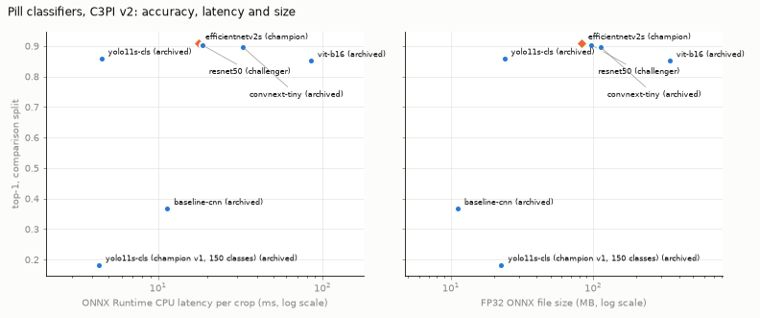

In [4]:
figure = TMP / "classifiers.png"
compare.plot(rows, figure)
show_image(figure, width=760)

## 2. Champion

In [5]:
run_id, version = champion("tujya-pill-classifier")
best = table.loc[table.run_id == run_id[:8]].iloc[0]
display(
    Markdown(
        f"**Champion: {best.arch}** (Registry version {version}, run `{run_id[:8]}`): "
        f"top-1 {best.top1:.4f}, top-5 {best.top5:.4f}, macro F1 {best.f1_macro:.4f}, "
        f"CPU latency {best.latency_ms:.1f} ms."
    )
)

**Champion: efficientnetv2s** (Registry version 8, run `f1ed9edd`): top-1 0.9089, top-5 0.9841, macro F1 0.8790, CPU latency 17.6 ms.

## 3. Confusion matrix of the champion

Share of each true class (rows) predicted as each class (columns), comparison split.

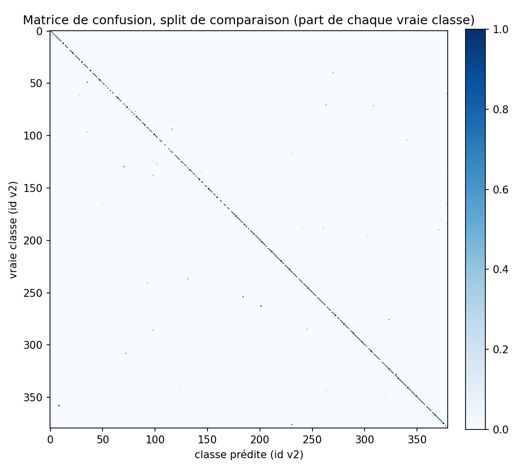

,true_class,true_name,predicted_class,predicted_name,count
0,130,GABAPENTIN 600MG TABLETS,70,GABAPENTIN 800MG TABLETS,3
1,138,FLUOXETINE 10MG CAP,98,INDOMETHACIN 25MG CAPSULES,3
2,254,GLIPIZIDE ER 10MG TAB,184,GLIPIZIDE ER 10MG TAB,3
3,308,DICLOXACILLIN SODIUM Capsules USP,72,DICLOXACILLIN SOD 250MG CAPS,3
4,4,DEPAKOTE SPRINKLES 125 MG,2,ALLOPURINOL 300MG TABS,2


In [6]:
show_image(artefact(run_id, "confusion/confusion_test_v2.png"), width=520)
top = pd.read_csv(artefact(run_id, "confusion/top_confusions_test_v2.csv"))
top.head(5)

## 4. Grad-CAM: a correct and a wrong prediction

Where the champion looks (`src/utils/gradcam.py`), on test crops saved by the Kaggle run.

*Grad-CAM, correct prediction*

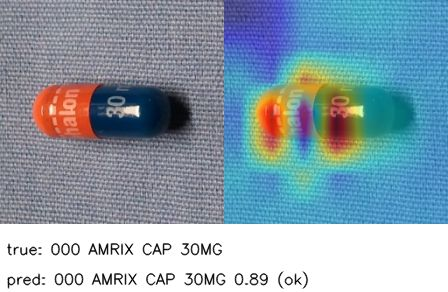

*Grad-CAM, wrong prediction*

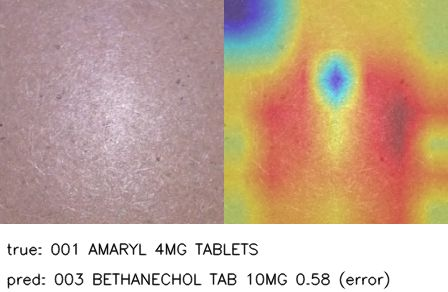

In [7]:
for name, title in (
    ("gradcam/gradcam_00_ok.png", "correct"),
    ("gradcam/gradcam_04_error.png", "wrong"),
):
    show_image(artefact(run_id, name), f"Grad-CAM, {title} prediction", width=560)